# EDA 

This notebook is a pipeline to create visualizations about different reporting factors for the OCR'd dataset given that naming conventions remain the same.

**Base Questions**

1. What occupations were most common in 1916 Boston, and how were they distributed across neighborhoods? 

2. Do particular trades or professions cluster spatially, and where? 

3. What proportion of listed individuals kept a home versus boarded, and does that vary by neighborhood or occupation? 

4. How many individuals listed in the Boston directory lived outside the city proper, and where are those residences concentrated? 

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import re

In [55]:
df = pd.read_csv('../data/ground_truth/sample_gt_visualizations_ONLY.csv')
df

,Year,Page,Surname,Given name,Occupation (as printed),Employer / affiliation,Work address (raw),Home address (raw),Residence marker,Transcription (working),Review status,Review notes
0,1916,161,NaN,NaN,insulated wire,A A Wire Co,93 Fed-eral,NaN,NaN,A A Wire Co insulated wire and cables 93 Fed-eral,needs review,advertisement
1,1916,161,NaN,NaN,children's dresses,A B Mfg Co,27 Kingston,NaN,NaN,"A B Mfg Co (Abe Borans, H F Brennan) children'...",needs review,NaN
2,1916,161,NaN,NaN,warehouse,NaN,NaN,NaN,NaN,A B SEE ELECTRIC ELEVATOR CO J R Jackson jr mg...,needs review,bold
3,1916,161,NaN,NaN,music,A D H Publishing Co,40 State rm 41,NaN,NaN,A D H Publishing Co music 40 State rm 41,needs review,NaN
4,1916,161,NaN,NaN,paper warehouse,A STORRS & BEMENT CO,140-150 Federal,NaN,NaN,A STORRS & BEMENT CO paper warehouse 140- 150 ...,needs review,bold; extra marker
...,...,...,...,...,...,...,...,...,...,...,...,...
937,1916,388,Cadigan,Russell J,clerk,NaN,70 Federal,Beverly Farms,h at,Russell J clerk 70 Federal h at Beverly Farms,NaN,NaN
938,1916,388,Cadigan,Timothy J,B F D,Boston Fire Department [?],Bristol,28 Buttonwood Dor,bds,"Timothy J, B F D, Bristol bds 28 Buttonwood Dor",NaN,NaN
939,1916,388,Cadigan,Timothy,fisherman,NaN,NaN,84 Forbes J P,h,Timothv fisherman h 84 Forbes J P,NaN,NaN
940,1916,388,Cadigan,Timothy,fisherman,NaN,NaN,5 Power's ct,h,Timothy fisherman h 5 Power's ct,NaN,NaN


In [56]:
df.columns

Index(['Year', 'Page', 'Surname', 'Given name', 'Occupation (as printed)',
       'Employer / affiliation', 'Work address (raw)', 'Home address (raw)',
       'Residence marker', 'Transcription (working)', 'Review status',
       'Review notes'],
      dtype='str')

## Question 1

Extract the neighborhood from the raw address

In [66]:
# Ordered from most specific/multi-word to shortest so nothing collides
NEIGHBORHOOD_ABBREVS = [
    (r"\bcamb['\s]?pt\b", 'Cambridgeport'),
    (r"\bb['\s]?line\b", 'Brookline'),
    (r'\bu\s*c\b', "Upham's Corner"),
    (r'\be\s*b\b', 'East Boston'),
    (r'\bs\s*b\b', 'South Boston'),
    (r'\bw\s*r\b', 'West Roxbury'),
    (r'\bh\s*p\b', 'Hyde Park'),
    (r'\bj\s*p\b', 'Jamaica Plain'),
    (r'\balls\b', 'Allston'),
    (r'\bchsn\b', 'Charlestown'),
    (r'\bfairm\b', 'Fairmount'),
    (r'\breadv\b', 'Readville'),
    (r'\bsomv\b', 'Somerville'),
    (r'\bcamb\b', 'Cambridge'),
    (r'\bdor\b', 'Dorchester'),
    (r'\bfen\b', 'Fenway'),
    (r'\bmat\b', 'Mattapan'),
    (r'\bnep\b', 'Neponset'),
    (r'\bros\b', 'Roslindale'),
    (r'\brox\b', 'Roxbury'),
    (r'\bbr\b', 'Brighton'),
]


def extract_neighborhood(addr):
  if pd.isna(addr):
    return None

  s = str(addr).lower()

  # Guard against company abbreviations from your list that contain "E B"
  s = re.sub(r'\be\s*b\s*(t\s*r\s*r\s*)?co\b', '', s)

  # Replace periods and commas with spaces so "Dor." or "S.B." match cleanly
  s = re.sub(r'[.,]', ' ', s)

  for pattern, name in NEIGHBORHOOD_ABBREVS:
    if re.search(pattern, s):
      return name

  return None

df['Neighborhood_Extracted'] = df['Home address (raw)'].apply(extract_neighborhood)

In [57]:
unique_occupations = df['Occupation (as printed)'].unique()

In [59]:
occupation_counts = df.groupby('Occupation (as printed)').size()

### Before Categories

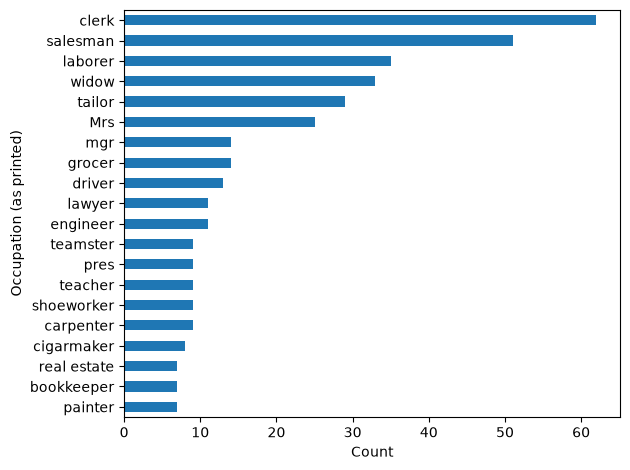

In [ ]:
df['Occupation (as printed)'].value_counts().head(20).plot(kind='barh').invert_yaxis()
plt.xlabel('Count')
plt.tight_layout()
plt.show()

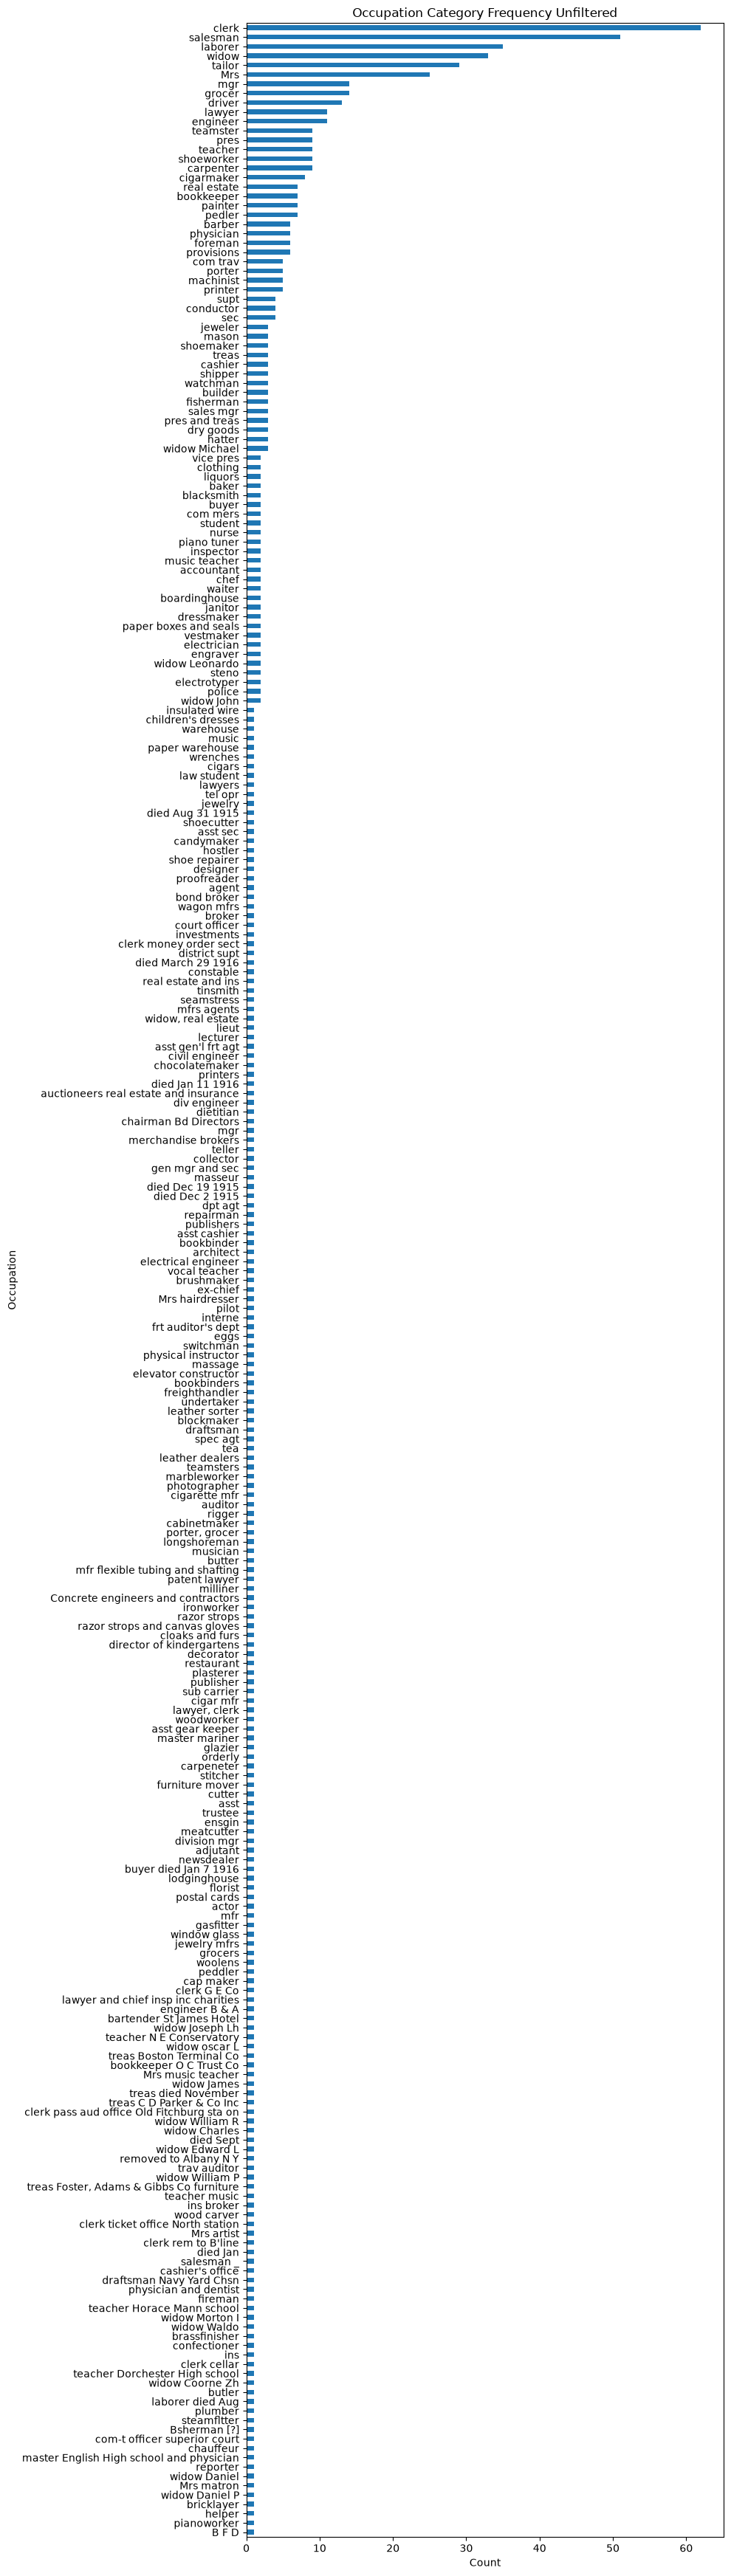

In [118]:
df['Occupation (as printed)'].value_counts().plot(
    kind='barh', 
    figsize=(10, 35)
).invert_yaxis()

plt.xlabel('Count')
plt.ylabel('Occupation')
plt.title('Occupation Category Frequency Unfiltered')
plt.tight_layout()
plt.savefig('../results/Occupation Category Frequency Unfiltered_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

### After Categories

In [69]:
def categorize_occupation(val):
  if pd.isna(val):
    return "Missing / Unknown"

  s = str(val).lower().strip()

  # 1. Life Status / Directory Notes (Check first so "widow, real estate" or "buyer died..." are handled intentionally)
  # Note: If you prefer to classify "buyer died Jan 7 1916" as Retail/Sales instead, move this block lower!
  if any(
      k in s
      for k in ["died", "widow", "removed to", "rem to", "mrs", "student"]
  ):
    if "teacher" in s:
      return "Education & Arts"
    if "hairdresser" in s:
      return "Personal & Domestic Service"
    if "artist" in s:
      return "Education & Arts"
    if "real estate" in s:
      return "Finance, Insurance & Real Estate"
    if "buyer" in s:
      return "Sales, Retail & Hospitality"
    if "treas" in s:
      return "Management & Executive"
    if "clerk" in s:
      return "Clerical & Office"
    if "laborer" in s:
      return "Manual Labor & Maintenance"
    return "Life Status / Non-Occupational"

  # 2. Public Safety, Government, Military & Legal
  if any(
      k in s
      for k in [
          "lawyer",
          "court",
          "constable",
          "fire",
          "sta ",
          "lieut",
          "ensgin",
          "adjutant",
          "ex-chief",
          "sub carrier",
          "navy yard",
          "inspector",
          "insp",
      ]
  ):
    return "Legal, Gov & Public Safety"

  # 3. Healthcare & Medicine
  if any(
      k in s
      for k in [
          "physician",
          "nurse",
          "interne",
          "dentist",
          "dietitian",
          "orderly",
          "masseur",
          "massage",
      ]
  ):
    return "Healthcare & Wellness"

  # 4. Education, Arts, Publishing & Entertainment
  if any(
      k in s
      for k in [
          "teacher",
          "school",
          "conservatory",
          "kindergarten",
          "lecturer",
          "music",
          "musician",
          "actor",
          "artist",
          "photographer",
          "publisher",
          "proofreader",
          "physical instructor",
          "piano tuner",
      ]
  ):
    return "Education, Arts & Publishing"

  # 5. Executive & Management
  if any(
      k in s
      for k in [
          "pres",
          "treas",
          "mgr",
          "supt",
          "chairman",
          "director",
          "trustee",
          "foreman",
          "sec",
      ]
  ):
    # Exclude 'clerk money order sect' from 'sec'
    if "money order sect" not in s:
      return "Management & Executive"

  # 6. Finance, Insurance & Real Estate
  if any(
      k in s
      for k in [
          "real estate",
          "ins",
          "broker",
          "investments",
          "accountant",
          "auditor",
          "teller",
          "cashier",
          "collector",
          "auctioneer",
      ]
  ):
    return "Finance, Insurance & Real Estate"

  # 7. Clerical & Office Support
  if any(k in s for k in ["clerk", "bookkeeper", "steno", "tel opr", "asst"]):
    return "Clerical & Office"

  # 8. Transportation, Maritime & Freight
  if any(
      k in s
      for k in [
          "driver",
          "teamster",
          "conductor",
          "switchman",
          "frt",
          "freight",
          "shipper",
          "longshoreman",
          "mariner",
          "pilot",
          "rigger",
          "hostler",
          "furniture mover",
          "b & a",
          "station",
          "sta on",
      ]
  ):
    return "Transportation & Maritime"

  # 9. Construction, Engineering & Skilled Trades
  if any(
      k in s
      for k in [
          "engineer",
          "architect",
          "draftsman",
          "carpenter",
          "carpeneter",
          "mason",
          "plumber",
          "electrician",
          "painter",
          "plasterer",
          "glazier",
          "decorator",
          "builder",
          "contractor",
          "elevator constructor",
          "gasfitter",
          "ironworker",
          "machinist",
          "tinsmith",
          "blacksmith",
          "brassfinisher",
          "cabinetmaker",
          "woodworker",
          "wood carver",
          "repairman",
      ]
  ):
    return "Engineering & Skilled Trades"

  # 10. Apparel, Textiles & Leather Manufacturing
  if any(
      k in s
      for k in [
          "tailor",
          "dress",
          "seamstress",
          "clothing",
          "cloaks",
          "furs",
          "milliner",
          "hatter",
          "cap maker",
          "vestmaker",
          "stitcher",
          "cutter",
          "woolens",
          "shoe",
          "leather",
          "gloves",
          "designer",
      ]
  ):
    return "Apparel, Textiles & Leather"

  # 11. General Manufacturing & Printing
  if any(
      k in s
      for k in [
          "mfr",
          "cigar",
          "cigarette",
          "printer",
          "bookbinder",
          "engraver",
          "electrotyper",
          "brushmaker",
          "blockmaker",
          "tubing",
          "wrenches",
          "wire",
          "paper boxes",
          "razor strops",
          "window glass",
          "postal cards",
      ]
  ):
    return "Manufacturing & Printing"

  # 12. Food, Hospitality, Retail & Sales
  if any(
      k in s
      for k in [
          "sales",
          "com trav",
          "com mers",
          "agent",
          "agt",
          "buyer",
          "grocer",
          "baker",
          "candy",
          "chocolate",
          "confectioner",
          "chef",
          "waiter",
          "bartender",
          "restaurant",
          "boardinghouse",
          "lodginghouse",
          "liquors",
          "meatcutter",
          "provisions",
          "eggs",
          "tea",
          "butter",
          "pedler",
          "peddler",
          "newsdealer",
          "florist",
          "jewel",
          "dry goods",
          "warehouse",
          "yacht club",
      ]
  ):
    return "Sales, Retail & Hospitality"

  # 13. Personal, Domestic & Manual Labor
  if any(
      k in s
      for k in [
          "laborer",
          "porter",
          "janitor",
          "watchman",
          "butler",
          "barber",
          "hairdresser",
          "undertaker",
          "fisherman",
          "fireman",
          "gear keeper",
      ]
  ):
    return "Manual Labor & Personal Service"

  return "Other / Unclassified"


df["Occupation_Category"] = df["Occupation (as printed)"].apply(
    categorize_occupation
)

In [70]:
print(df["Occupation_Category"].value_counts())

# Inspect anything that wasn't caught by the rules
print(
    df[df["Occupation_Category"] == "Other / Unclassified"][
        "Occupation (as printed)"
    ].unique()
)

Occupation_Category
Missing / Unknown                   215
Sales, Retail & Hospitality         126
Life Status / Non-Occupational       89
Clerical & Office                    81
Apparel, Textiles & Leather          65
Engineering & Skilled Trades         60
Management & Executive               59
Manual Labor & Personal Service      57
Transportation & Maritime            39
Manufacturing & Printing             36
Finance, Insurance & Real Estate     30
Education, Arts & Publishing         29
Legal, Gov & Public Safety           28
Healthcare & Wellness                15
Other / Unclassified                  9
Education & Arts                      2
Personal & Domestic Service           1
Manual Labor & Maintenance            1
Name: count, dtype: int64
<StringArray>
['marbleworker', 'Bsherman [?]',    'chauffeur',       'police',
   'bricklayer',       'helper',  'pianoworker',        'B F D']
Length: 8, dtype: str


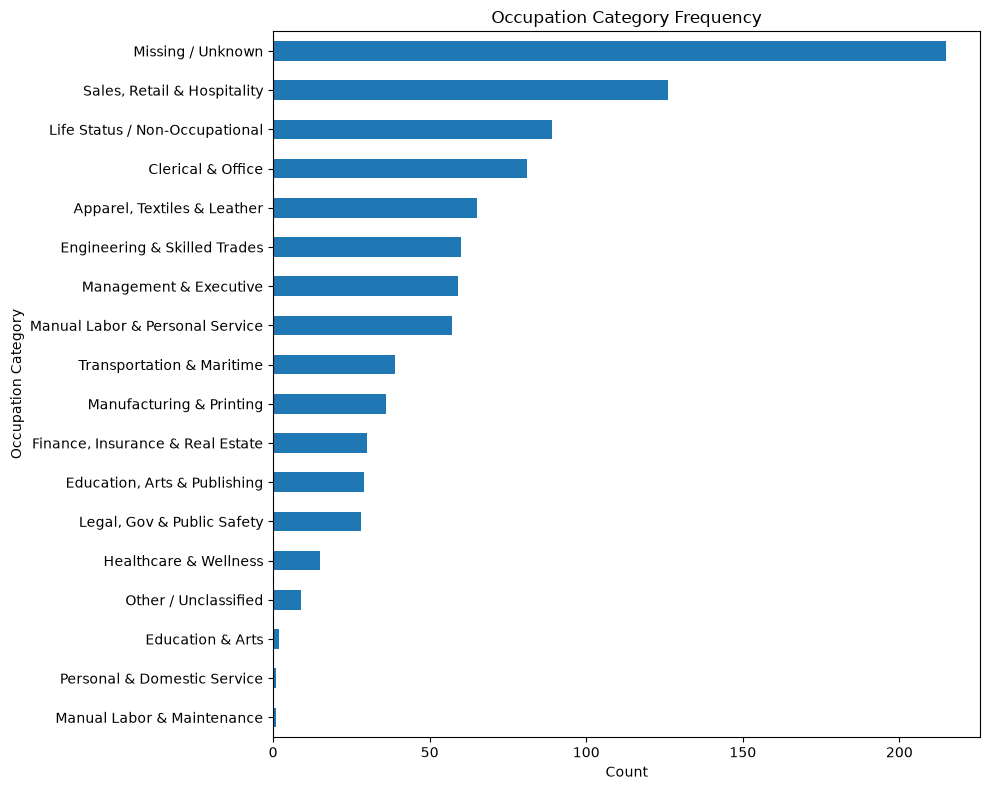

In [117]:
df['Occupation_Category'].value_counts().plot(
    kind='barh', 
    figsize=(10, 8)
).invert_yaxis()

plt.xlabel('Count')
plt.ylabel('Occupation Category')
plt.title('Occupation Category Frequency')
plt.tight_layout()
plt.savefig('../results/Occupation Category Frequency_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

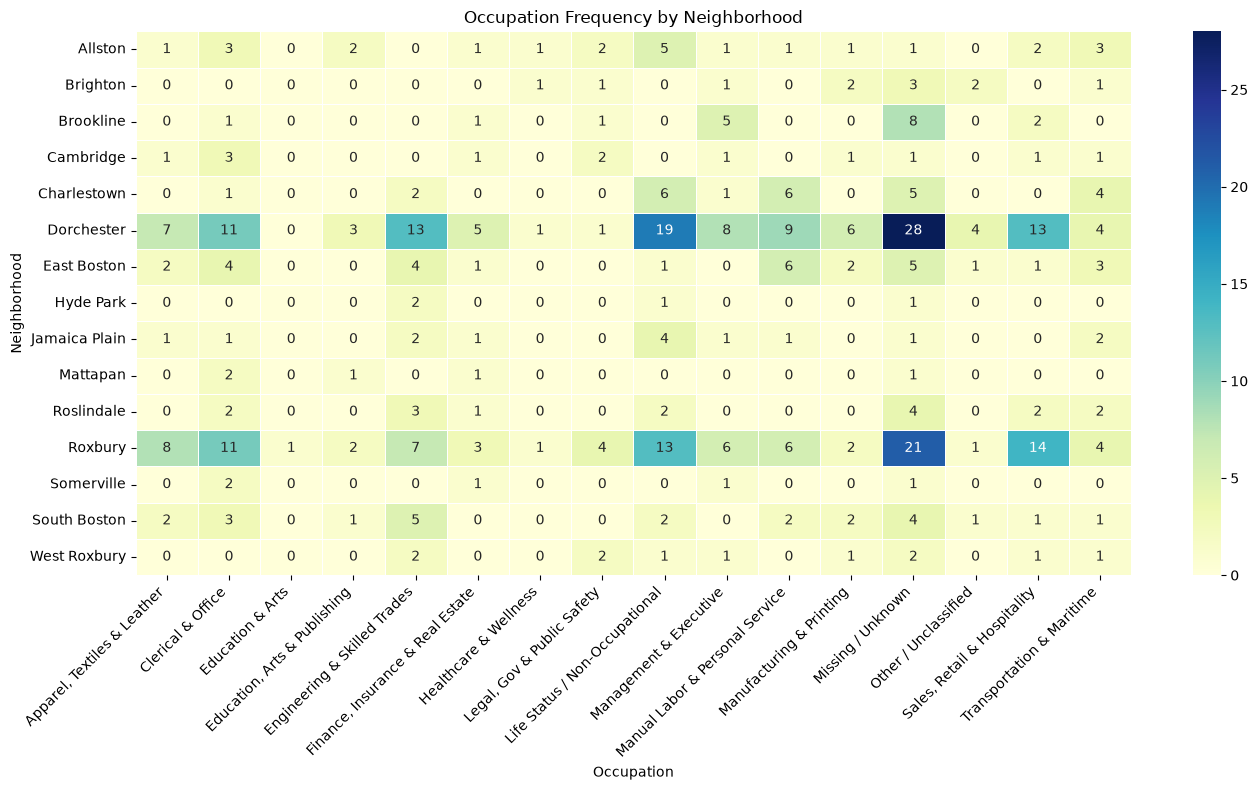

In [116]:
# Create a cross-tabulation of Neighborhood vs. Occupation_Category
# Filter to top 15 neighborhoods if you have dozens of minor variants
top_neighborhoods = df['Neighborhood_Extracted'].value_counts().head(15).index
ct = pd.crosstab(
    df[df['Neighborhood_Extracted'].isin(top_neighborhoods)]['Neighborhood_Extracted'],
    df['Occupation_Category'],
)

# Plot the heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    ct,
    annot=True,  
    fmt='d',  
    cmap='YlGnBu', 
    linewidths=0.5,
)

plt.title('Occupation Frequency by Neighborhood')
plt.xlabel('Occupation')
plt.ylabel('Neighborhood')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/Occupation Frequency by Neighborhood_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

## Question 2

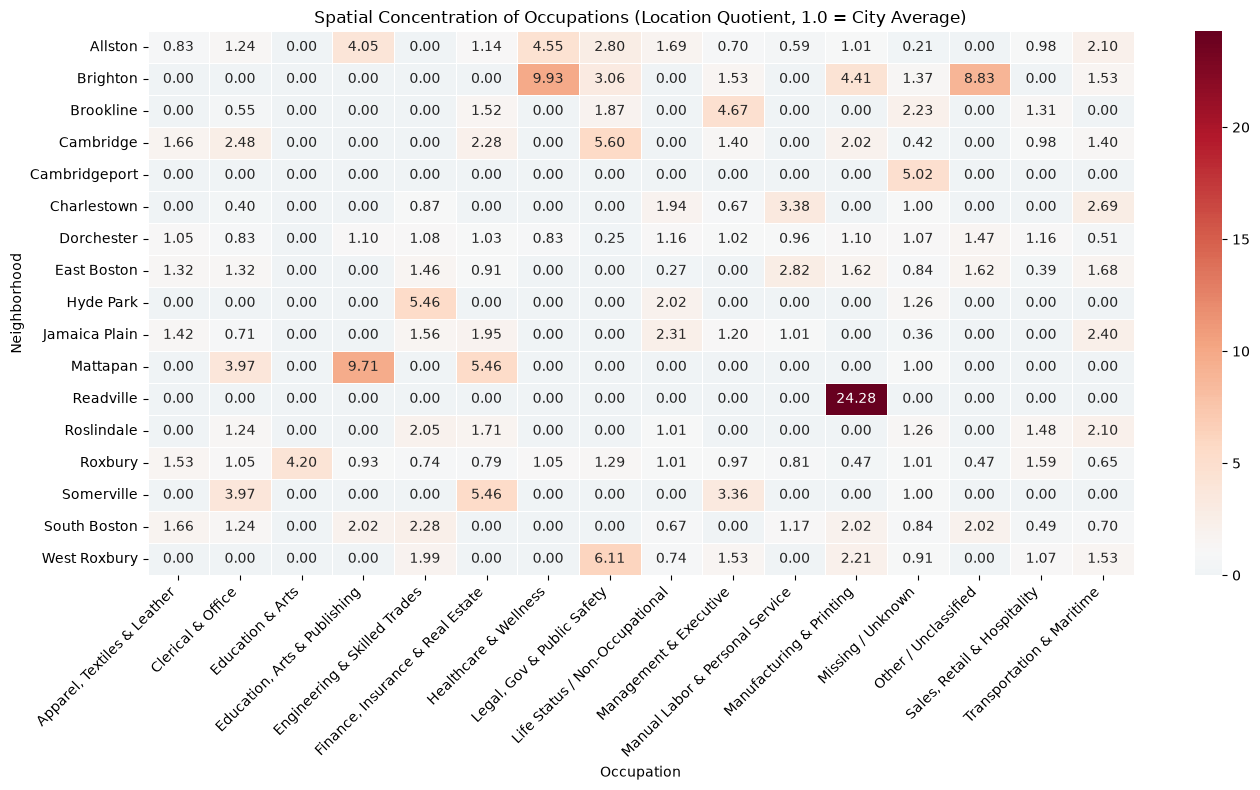

In [115]:
# Create raw cross-tabulation
ct = pd.crosstab(df['Neighborhood_Extracted'], df['Occupation_Category'])

# Calculate Location Quotient (LQ)
# LQ = (Occupation in Neighborhood / Total in Neighborhood) / (Occupation in City / Total in City)
row_shares = ct.div(ct.sum(axis=1), axis=0)
city_shares = ct.sum(axis=0) / ct.values.sum()
lq = row_shares.div(city_shares, axis=1)

# Plot LQ Heatmap (values > 1.0 indicate spatial clustering)
plt.figure(figsize=(14, 8))
sns.heatmap(
    lq,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=1.0,
    linewidths=0.5,
)
plt.title(
    'Spatial Concentration of Occupations (Location Quotient, 1.0 = City Average)'
)
plt.xlabel('Occupation')
plt.ylabel('Neighborhood')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/Spatial Concentration of Occupations_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

## Question 3

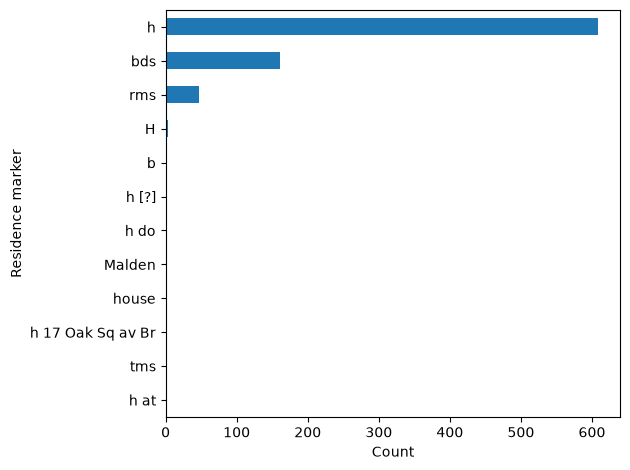

In [83]:
df['Residence marker'].value_counts().head(20).plot(kind='barh').invert_yaxis()
plt.xlabel('Count')
plt.tight_layout()
plt.show()

In [88]:
HOUSING_ABBREVS = [
    (r'\b(house|ho)\b', 'House'),
    (r'\b(bds|boards)\b', 'Boards'),
    (r'\b(rms|rooms)\b', 'Rooms'),
    (r'\bh\b', 'House'),
    (r'\bb\b', 'Boards'),
]


def extract_housing_type(addr):
  if pd.isna(addr):
    return None

  s = str(addr).lower()

  for pattern, name in HOUSING_ABBREVS:
    if re.search(pattern, s):
      return name

  return None


df['Housing_type_extracted'] = df['Residence marker'].apply(
    extract_housing_type
)

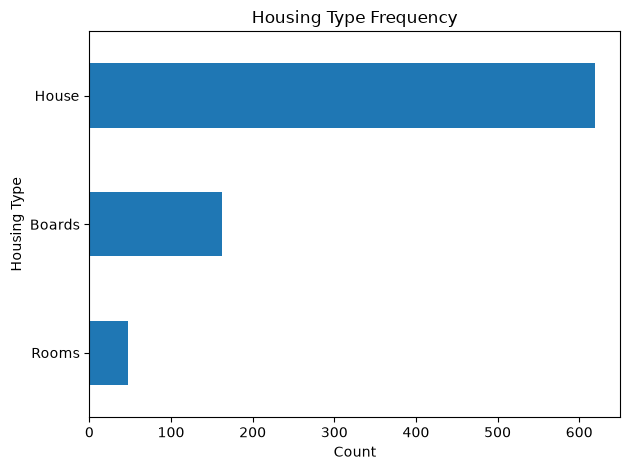

In [114]:
df['Housing_type_extracted'].value_counts().head(20).plot(kind='barh').invert_yaxis()
plt.xlabel('Count')
plt.ylabel('Housing Type')
plt.title('Housing Type Frequency')
plt.tight_layout()
plt.savefig('../results/Housing Types_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

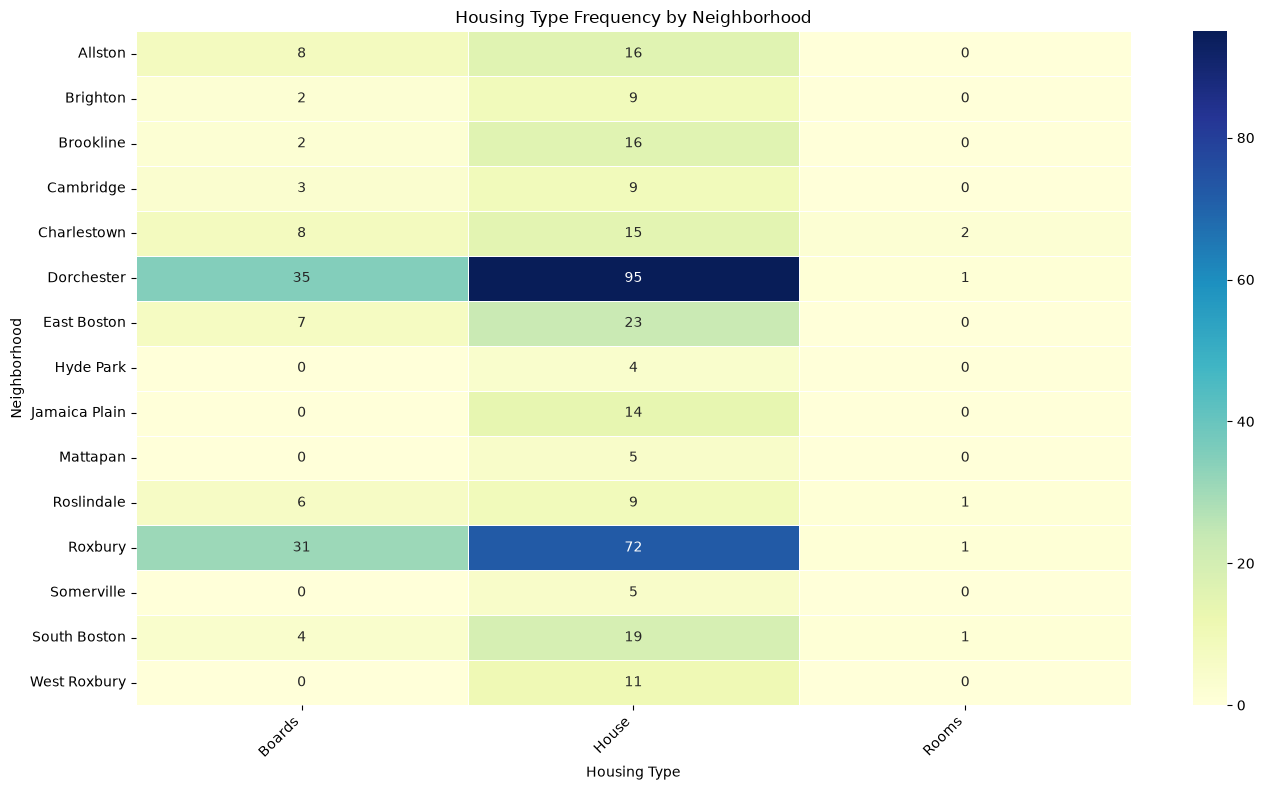

In [111]:
ct = pd.crosstab(
    df[df['Neighborhood_Extracted'].isin(top_neighborhoods)]['Neighborhood_Extracted'],
    df['Housing_type_extracted'],
)

# Plot the heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    ct,
    annot=True,  
    fmt='d',  
    cmap='YlGnBu', 
    linewidths=0.5,
)

plt.title('Housing Type Frequency by Neighborhood')
plt.xlabel('Housing Type')
plt.ylabel('Neighborhood')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/Housing Type Frequency by Neighborhood_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

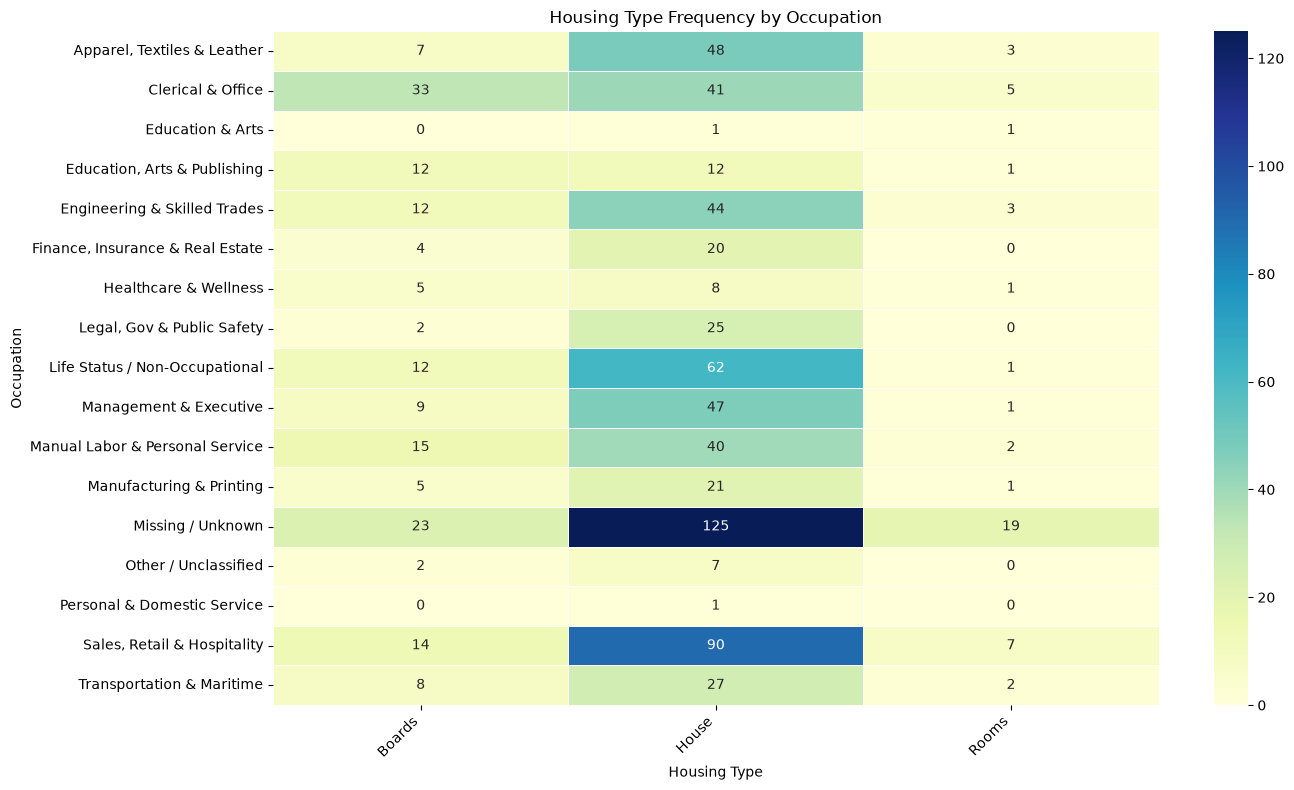

In [112]:
ct = pd.crosstab(
    df['Occupation_Category'],
    df['Housing_type_extracted'],
)

# Plot the heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    ct,
    annot=True,  
    fmt='d',  
    cmap='YlGnBu', 
    linewidths=0.5,
)

plt.title('Housing Type Frequency by Occupation')
plt.xlabel('Housing Type')
plt.ylabel('Occupation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/Housing Type Frequency by Occupation_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

## Question 4

In [92]:
df['boston_proper'] = (
    df['Neighborhood_Extracted']
    .str.contains(r'\bboston\b', case=False, na=False)
    .astype(int)
)

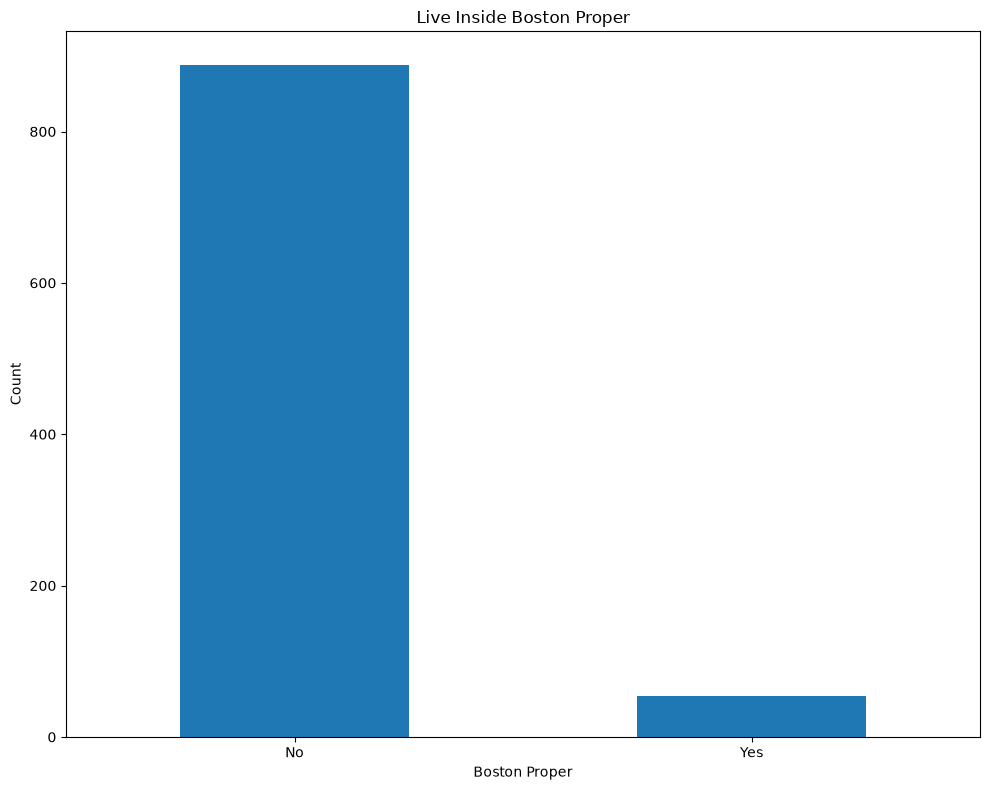

In [107]:
df['boston_proper'].map({1: 'Yes', 0: 'No'}).value_counts().plot(
    kind='bar',
    figsize=(10, 8),
    rot=0,  
)
plt.xlabel('Boston Proper')
plt.ylabel('Count')
plt.title('Live Inside Boston Proper')
plt.tight_layout()
plt.savefig('../results/Live Inside Boston Proper_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()

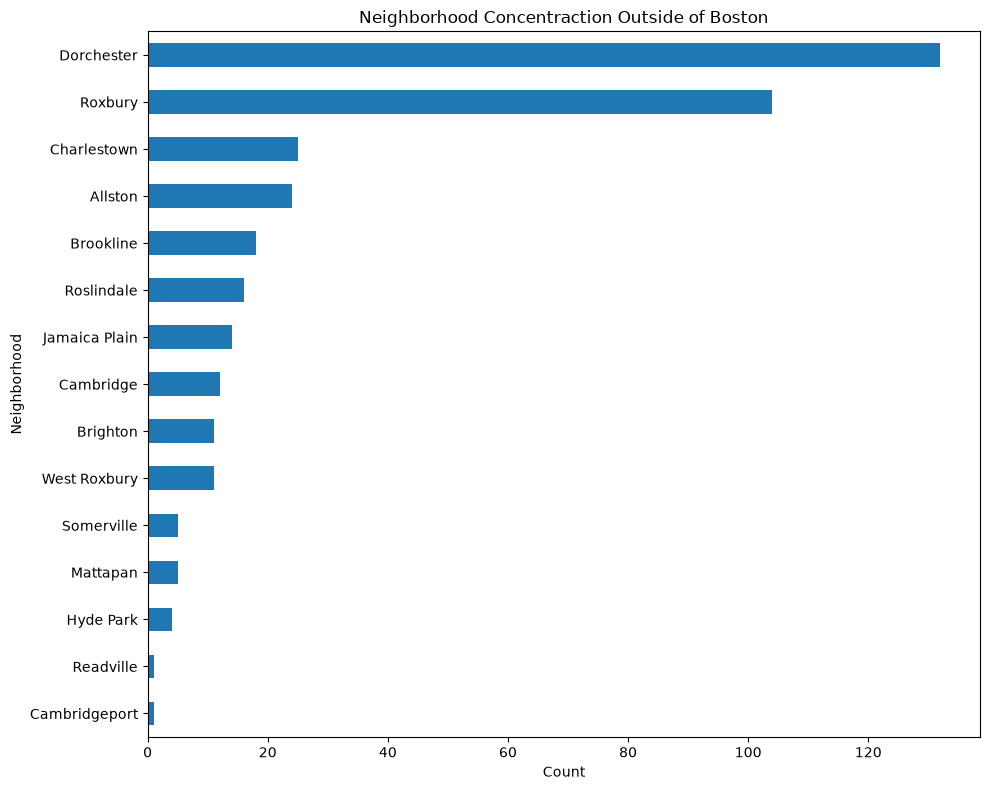

In [106]:
df[df['boston_proper'] == 0]['Neighborhood_Extracted'].value_counts().plot(
    kind='barh',
    figsize=(10, 8),
).invert_yaxis()  # Puts the largest neighborhood at the top

plt.xlabel('Count')
plt.ylabel('Neighborhood')
plt.title('Neighborhood Concentraction Outside of Boston')
plt.tight_layout()
plt.savefig('../results/Neighborhood Concentraction Outside of Boston_GT_ONLY.png', dpi=300, bbox_inches='tight')
plt.show()